# 03 · Signatures — embryonic-development module scores & Gate 2

The three embryonic modules — **Gast** (gastrulation), **pSom** (posterior somitogenesis), **Crest**
(neural crest) — were scored in 01 against the shared **union** control pool and graph-smoothed for
geography. Here we render them as deliverables (**raw** per-cell scores, so SmartSeq2 sampling noise
is visible) and evaluate **Gate 2**.

**Gate 2 (verdict: NO-GO — pattern absent at single-cell resolution).** The non-branching GO case
(§1–2) requires the embryonic programs to be *present*: Gast/pSom organized along the axis with Crest
an inverse/terminal gradient. On this **360-cell** SmartSeq2 TNBC manifold the module geography is
**absent in the raw per-cell scores** (Gast↔pseudotime raw ρ=−0.08, pSom +0.02, Crest −0.03 — all
≈0) and appears **only after graph-smoothing**. A permutation null (below) shows that smoothed
structure is indistinguishable from what smoothing manufactures from random scores on this 360-cell
graph: every reported gradient has p ≥ 0.26 against the null, whose 95% CI is ≈ ±0.9 at this cell
count. Worse, smoothing **flips the sign** of the one real single-cell relationship — Crest↔Gast and
Crest↔pSom are −0.43/−0.55 raw but +0.44/+0.10 smoothed — so the smoothed "geography" contradicts the
raw biology rather than revealing it. Per §2 ("NO-GO where the pattern is absent"), **Gate 2 = NO-GO**.
The unconditional EMT-TF expression step still follows as notebook 04.
Deliverable: `signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures scored + smoothed in 01/02)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation','pSom':'Somitogenesis','Crest':'Neural Crest'}
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')
print('cells:', adata.shape[0], '| raw module means:', adata.obs[['Gast','pSom','Crest']].mean().round(4).to_dict())

Gast: 72/81 genes present
pSom: 86/98 genes present
Crest: 101/104 genes present
cells: 360 | raw module means: {'Gast': -0.22, 'pSom': 0.1058, 'Crest': -0.0665}


### Gate 2 — module geography, tested against a smoothing null
The apparent geography lives only in the graph-smoothed scores, so the decisive test is whether that
smoothed structure exceeds a **permutation null**: permute each raw per-cell score across cells and
re-smooth on the same kNN graph (itself built from these genes), then compare. At 360 cells this null
is wide. Report smoothed point estimates, but judge GO/NO-GO against the null and against the raw
single-cell signal. Deliverable UMAPs below show the **raw** scores.

In [ ]:
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('geography correlations (raw vs smoothed):')
for x,y in [('Gast','pSom'),('Crest','Gast'),('Crest','pSom')]:
    rr = np.corrcoef(adata.obs[x], adata.obs[y])[0,1]
    rs = np.corrcoef(adata.obs[x+'_sm'], adata.obs[y+'_sm'])[0,1]
    flip = ' <- SIGN FLIP' if np.sign(rr)!=np.sign(rs) and abs(rr)>0.2 else ''
    print(f'  {x}<->{y}: raw {rr:+.2f} | smoothed {rs:+.2f}{flip}')
print('gradient along pseudotime (Spearman rho, raw vs smoothed):')
for m in ['Gast','pSom','Crest']:
    print(f'  {m}: raw {spearmanr(t, adata.obs[m])[0]:+.3f} | smoothed {spearmanr(t, adata.obs[m+"_sm"])[0]:+.3f}')

# --- permutation null: is the smoothed geography more than a smoothing artifact? ---
import scipy.sparse as sp
A = (adata.obsp['connectivities']>0).astype(float); A = A + sp.eye(A.shape[0])
A = sp.diags(1/np.asarray(A.sum(1)).ravel()) @ A
def _smooth(v, k=3):
    x = v.astype(float).copy()
    for _ in range(k): x = A @ x
    return np.asarray(x).ravel()
rng = np.random.default_rng(0)
G = adata.obs['Gast'].values.astype(float); P = adata.obs['pSom'].values.astype(float); C = adata.obs['Crest'].values.astype(float)
real = {'Gast~pt': spearmanr(t,_smooth(G))[0], 'pSom~pt': spearmanr(t,_smooth(P))[0], 'Crest~pt': spearmanr(t,_smooth(C))[0]}
N = 500; null = {k: np.empty(N) for k in real}
for i in range(N):
    null['Gast~pt'][i]  = spearmanr(t,_smooth(G[rng.permutation(G.size)]))[0]
    null['pSom~pt'][i]  = spearmanr(t,_smooth(P[rng.permutation(P.size)]))[0]
    null['Crest~pt'][i] = spearmanr(t,_smooth(C[rng.permutation(C.size)]))[0]
print(f'\npermutation null (n={N}, {adata.n_obs} cells) — smoothed pseudotime gradients vs null:')
allns = True
for k in ['Gast~pt','pSom~pt','Crest~pt']:
    lo,hi = np.percentile(null[k],[2.5,97.5]); p = (np.sum(np.abs(null[k])>=abs(real[k]))+1)/(N+1)
    sig = 'SIGNIFICANT' if p<0.05 else 'not significant'
    allns = allns and (p>=0.05)
    print(f'  {k}: real ={real[k]:+.3f} | null 95%CI=[{lo:+.2f},{hi:+.2f}] | p={p:.3f} ({sig})')
print('\nGate 2 = NO-GO: the embryonic-module pattern is absent in the raw per-cell scores, and the')
print('smoothed geography is not distinguishable from a graph-smoothing artifact (all gradients p>=0.05;')
print('smoothing even flips the sign of the raw Crest<->Gast/pSom relationships). Pattern does not reproduce.')
print('Gate 3 = NA (branching-only; chain halts at Gate 2 NO-GO).')


geography correlations (raw vs smoothed):
  Gast<->pSom: raw +0.07 | smoothed +0.04
  Crest<->Gast: raw -0.43 | smoothed +0.44 <- SIGN FLIP
  Crest<->pSom: raw -0.55 | smoothed +0.10 <- SIGN FLIP
gradient along pseudotime (Spearman rho, raw vs smoothed):
  Gast: raw -0.084 | smoothed -0.777
  pSom: raw +0.018 | smoothed +0.313
  Crest: raw -0.031 | smoothed -0.607

permutation null (n=500, 360 cells) — smoothed pseudotime gradients vs null:
  Gast~pt: real =-0.777 | null 95%CI=[-0.90,+0.90] | p=0.257 (not significant)
  pSom~pt: real =+0.313 | null 95%CI=[-0.91,+0.87] | p=0.697 (not significant)
  Crest~pt: real =-0.607 | null 95%CI=[-0.90,+0.88] | p=0.431 (not significant)

Gate 2 = NO-GO: the embryonic-module pattern is absent in the raw per-cell scores, and the
smoothed geography is not distinguishable from a graph-smoothing artifact (all gradients p>=0.05;
smoothing even flips the sign of the raw Crest<->Gast/pSom relationships). Pattern does not reproduce.
Gate 3 = NA (branching-o

### Signature maps in the house linear layout (quick look, smoothed for geography)
Three-panel overview on `X_umap_lin` (pseudotime left→right). These smoothed panels are for reading
geography; the per-module deliverables below show **raw** scores.

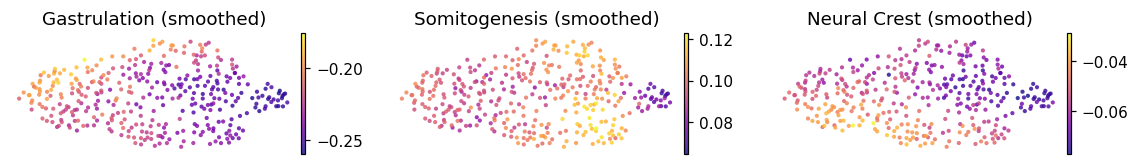

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, axes = plt.subplots(1,3, figsize=(10.5,1.6))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m+'_sm', cmap='plasma', alpha=.8, size=30, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title+' (smoothed)')
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
fig.tight_layout(); plt.show()

### Per-module signature figures + colorbars (deliverables)
House style: `figsize=(3.5,1.5)`, pseudotime left→right, `size=30`, plasma colormap, **raw** per-cell
score (SmartSeq2 sampling visible), colorbar ticks data-driven.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


<ipython-input-6-98d6ca95c201>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
<ipython-input-6-98d6ca95c201>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
<ipython-input-6-98d6ca95c201>:16: UserWarning: Adding colorbar to a different Figure <Figure size 350x150 with 1 Axes> than <Figure size 66x100 with 1 Axes> which fig.colorbar is called on.
  cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)


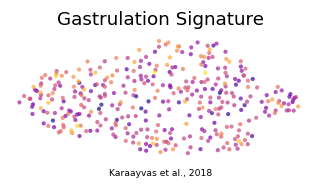

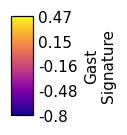

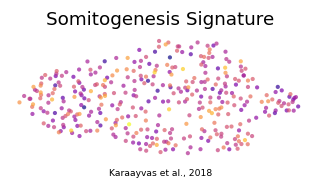

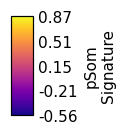

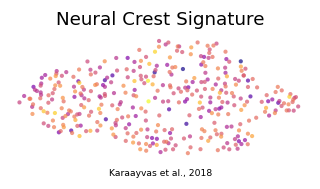

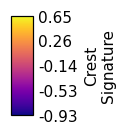

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(3.5,1.5))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=30, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
    ax.text(.5,-.12,'Karaayvas et al., 2018', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    plt.show()
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [ ]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (360, 16243)
